In [1]:
import pandas as pd
import numpy as np
import torch

from transformers import AutoModel, AutoTokenizer, get_linear_schedule_with_warmup

import os
import sys
from dotenv import load_dotenv

sys.path.insert(0, "..")
from preprocessing_data import TARGETS, make_labels, make_split, narrative_text
from utilis.metrics import score_event
from utilis.results import new_results_dir, summary_markdown

C:\Users\kzb262\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
MODEL_NAME = "bert-base-uncased"
MAX_LENGTH = 512

# If the GPU runs out of memory: BATCH_SIZE = 8 and ACCUMULATE = 2
BATCH_SIZE = 16
ACCUMULATE = 1

SEED = 42

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA T1000 8GB


In [4]:
load_dotenv()

df = pd.read_csv(os.getenv("DATA_PATH"), low_memory=False)
df.columns = [" ".join(str(c).split()) for c in df.columns]

print("Dataset shape:", df.shape)

Dataset shape: (10261, 2040)


In [5]:
target_names = list(TARGETS)

y = make_labels(df).to_numpy(dtype=np.float32)

print("Target shape:", y.shape)
print("Positive reports per category:", y.sum(axis=0).astype(int))

Target shape: (10261, 6)
Positive reports per category: [2541 2042 1848 1657 1430 1373]


In [6]:
# Reporter narratives only (Narrative 1, 2, ... joined). No synopsis, callbacks or coded fields.
text = narrative_text(df)

print("Columns used:", [c for c in df.columns if c.startswith("Person Narrative / ")])

for i in range(3):
    print(f"\nReport {i} (ACN {df['ACN'].iloc[i]}), {len(text.iloc[i]):,} characters:")
    print(text.iloc[i])

Columns used: ['Person Narrative / Narrative 1', 'Person Narrative / Narrative 2', 'Person Narrative / Narrative 3', 'Person Narrative / Narrative 4', 'Person Narrative / Narrative 5', 'Person Narrative / Narrative 6', 'Person Narrative / Narrative 7', 'Person Narrative / Narrative 8', 'Person Narrative / Narrative 9', 'Person Narrative / Narrative 10']

Report 0 (ACN 42788), 643 characters:
Prior to departure, I may have failed to do a pre-departure Class II Brake Test. Once I realized (within 15 feet), I stopped and we did a Class II Brake Test. Train A, Track X, location [was] Station X. At departure time, I was operating from the cab of car six in an eight car consist at [the] bottom of [the] stairs to [the] platform. [I] believed that a brake test had been done by a Qualified Mechanical Person. Closed [the] doors at leaving time and gave two [buzzers] to go. [The] train moved about 10 to 15 feet and stopped. [The] Engineer advised a brake test needed to be completed. Went to [the]

In [7]:
# Same split as the baselines: duplicate narratives stay together
train_idx, val_idx, test_idx = make_split(make_labels(df), text, seed=SEED)

for name, idx in [
    ("Train", train_idx),
    ("Validation", val_idx),
    ("Test", test_idx)
]:
    print(f"{name}: {len(idx):,} reports")
    print("Positive labels:", y[idx].sum(axis=0).astype(int))

Train: 7,182 reports
Positive labels: [1781 1431 1295 1160 1001  958]
Validation: 1,539 reports
Positive labels: [380 306 278 248 213 206]
Test: 1,540 reports
Positive labels: [380 305 275 249 216 209]


In [8]:
split_path = "../results/split_acn.csv"

split_table = pd.DataFrame({"ACN": df["ACN"].to_numpy(), "split": ""})
split_table.loc[train_idx, "split"] = "training"
split_table.loc[val_idx, "split"] = "validation"
split_table.loc[test_idx, "split"] = "test"

if not os.path.exists(split_path):
    split_table.to_csv(split_path, index=False)
    print("Saved split to", split_path)
else:
    saved = pd.read_csv(split_path)

    for name in ["training", "validation", "test"]:
        saved_acn = set(saved.loc[saved["split"] == name, "ACN"])
        new_acn = set(split_table.loc[split_table["split"] == name, "ACN"])
        assert saved_acn == new_acn, (
            f"STOP: the {name} reports are not the same as in {split_path}. "
            "This notebook is not using the shared split."
        )

    print("Split matches", split_path)

Split matches ../results/split_acn.csv


In [9]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Cut every report to MAX_LENGTH tokens; padding is added per batch later
encoded = tokenizer(text.tolist(), truncation=True, max_length=MAX_LENGTH)

# Length of every report before cutting
n_tokens = np.array([
    len(ids) for ids in tokenizer(text.tolist(), truncation=False, verbose=False)["input_ids"]
])

print("Median tokens per report:", int(np.median(n_tokens)))
print("Longest report:", n_tokens.max(), "tokens")
print(f"Reports over {MAX_LENGTH} tokens: {(n_tokens > MAX_LENGTH).sum():,} of {len(n_tokens):,} "
      f"({(n_tokens > MAX_LENGTH).mean():.1%})")

for name, idx in [
    ("Train", train_idx),
    ("Validation", val_idx),
    ("Test", test_idx)
]:
    print(f"{name}: {(n_tokens[idx] > MAX_LENGTH).sum():,} over {MAX_LENGTH} tokens")

Median tokens per report: 138
Longest report: 3933 tokens
Reports over 512 tokens: 531 of 10,261 (5.2%)
Train: 395 over 512 tokens
Validation: 69 over 512 tokens
Test: 67 over 512 tokens


In [10]:
from torch.utils.data import DataLoader


def collate(rows):
    # Pad only to the longest report in this batch
    batch = tokenizer.pad(
        {
            "input_ids": [encoded["input_ids"][i] for i in rows],
            "attention_mask": [encoded["attention_mask"][i] for i in rows],
        },
        return_tensors="pt"
    )
    return batch["input_ids"], batch["attention_mask"], torch.from_numpy(y[rows])


train_loader = DataLoader(
    train_idx.tolist(), batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate
)

val_loader = DataLoader(
    val_idx.tolist(), batch_size=BATCH_SIZE, collate_fn=collate
)

test_loader = DataLoader(
    test_idx.tolist(), batch_size=BATCH_SIZE, collate_fn=collate
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 449
Validation batches: 97
Testing batches: 97


In [11]:
torch.manual_seed(SEED)
np.random.seed(SEED)

bert = AutoModel.from_pretrained(MODEL_NAME).to(device)

# CLS vector -> dropout -> one output per event
head = torch.nn.Sequential(
    torch.nn.Dropout(0.1),
    torch.nn.Linear(bert.config.hidden_size, y.shape[1])
).to(device)


def forward(input_ids, attention_mask):
    hidden = bert(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
    return head(hidden[:, 0])


params = list(bert.parameters()) + list(head.parameters())

print("Device:", device)
print("Trainable parameters:", f"{sum(p.numel() for p in params):,}")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 502.18it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Device: cuda
Trainable parameters: 109,486,854


In [12]:
epochs = 5
patience = 2

steps_per_epoch = int(np.ceil(len(train_loader) / ACCUMULATE))
total_steps = steps_per_epoch * epochs

criterion = torch.nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(params, lr=2e-5)
scheduler = get_linear_schedule_with_warmup(
    optimizer, int(0.10 * total_steps), total_steps
)

use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler(enabled=use_amp)

print("Optimizer steps:", total_steps, "| warmup:", int(0.10 * total_steps))

Optimizer steps: 2245 | warmup: 224


In [13]:
from sklearn.metrics import average_precision_score

# Results and checkpoint folders (a new numbered folder if text_only already has results)
results_dir = new_results_dir("text_only", "../results")
checkpoint_dir = os.path.join("..", "checkpoints", results_dir.name)
os.makedirs(checkpoint_dir, exist_ok=True)
checkpoint_path = os.path.join(checkpoint_dir, f"bert_seed{SEED}.pt")

print("Results:", results_dir)
print("Checkpoint:", checkpoint_path)


def predict(loader):
    bert.eval()
    head.eval()
    probs, targets, total_loss = [], [], 0

    with torch.no_grad():
        for input_ids, attention_mask, labels in loader:
            with torch.autocast(device.type, enabled=use_amp):
                logits = forward(input_ids.to(device), attention_mask.to(device)).float()

            total_loss += criterion(logits, labels.to(device)).item() * len(labels)
            probs.append(torch.sigmoid(logits).cpu())
            targets.append(labels)

    y_true = torch.cat(targets).numpy().astype(int)
    y_prob = torch.cat(probs).numpy()

    return y_true, y_prob, total_loss / len(y_true)

Results: ..\results\text_only
Checkpoint: ..\checkpoints\text_only\bert_seed42.pt


In [14]:
best_ap = -1
wait = 0
history = []

for epoch in range(epochs):
    bert.train()
    head.train()
    train_loss = 0
    optimizer.zero_grad()

    for step, (input_ids, attention_mask, labels) in enumerate(train_loader):
        labels = labels.to(device)

        with torch.autocast(device.type, enabled=use_amp):
            logits = forward(input_ids.to(device), attention_mask.to(device)).float()

        loss = criterion(logits, labels)
        scaler.scale(loss / ACCUMULATE).backward()

        if (step + 1) % ACCUMULATE == 0 or step + 1 == len(train_loader):
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            optimizer.zero_grad()

        train_loss += loss.item() * len(labels)

    train_loss /= len(train_idx)

    val_true, val_prob, val_loss = predict(val_loader)
    val_ap = average_precision_score(val_true, val_prob, average=None).mean()

    history.append((train_loss, val_loss, val_ap))

    print(
        f"Epoch {epoch + 1:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val mean AP: {val_ap:.4f}"
    )

    if val_ap > best_ap:
        best_ap = val_ap
        best_epoch = epoch + 1
        torch.save({"bert": bert.state_dict(), "head": head.state_dict()}, checkpoint_path)
        wait = 0
    else:
        wait += 1
        if wait >= patience:
            print("Early stopping")
            break

# Go back to the best epoch
state = torch.load(checkpoint_path, map_location=device)
bert.load_state_dict(state["bert"])
head.load_state_dict(state["head"])

print("Best epoch:", best_epoch, "| Val mean AP:", round(best_ap, 4))

Epoch 01 | Train Loss: 0.3156 | Val Loss: 0.2011 | Val mean AP: 0.8240
Epoch 02 | Train Loss: 0.1704 | Val Loss: 0.1701 | Val mean AP: 0.8645
Epoch 03 | Train Loss: 0.1336 | Val Loss: 0.1766 | Val mean AP: 0.8667
Epoch 04 | Train Loss: 0.1065 | Val Loss: 0.1774 | Val mean AP: 0.8664
Epoch 05 | Train Loss: 0.0868 | Val Loss: 0.1769 | Val mean AP: 0.8677
Best epoch: 5 | Val mean AP: 0.8677


In [15]:
from sklearn.metrics import f1_score

# Cutoffs come from validation; the test set is scored once
val_true, val_prob, _ = predict(val_loader)
y_true, y_prob, _ = predict(test_loader)

results = pd.DataFrame([
    dict(
        setting="Text",
        model="BERT",
        label=label,
        params=f"{MODEL_NAME}, seed {SEED}, best epoch {best_epoch}",
        **score_event(val_true[:, j], val_prob[:, j], y_true[:, j], y_prob[:, j]),
        n_test=len(y_true)
    )
    for j, label in enumerate(target_names)
])

y_pred = (y_prob >= results["threshold"].to_numpy()).astype(int)

macro_f1 = results["f1"].mean()
micro_f1 = f1_score(y_true, y_pred, average="micro")

print(results.set_index("label")[["threshold", "precision", "recall", "f1", "ap"]].round(3))
print("\nMean AP:", round(results["ap"].mean(), 3))
print("Macro F1:", round(macro_f1, 3))
print("Micro F1:", round(micro_f1, 3))

                     threshold  precision  recall     f1     ap
label                                                          
Station Ops               0.82      0.957   0.926  0.941  0.982
Speed - MAS               0.53      0.799   0.836  0.817  0.872
Emerg/Penalty Brake       0.40      0.881   0.887  0.884  0.934
Mechanical (less)         0.36      0.670   0.759  0.712  0.782
Signal - OBCS             0.44      0.761   0.810  0.785  0.851
Speed - TSR               0.37      0.865   0.890  0.877  0.930

Mean AP: 0.892
Macro F1: 0.836
Micro F1: 0.843


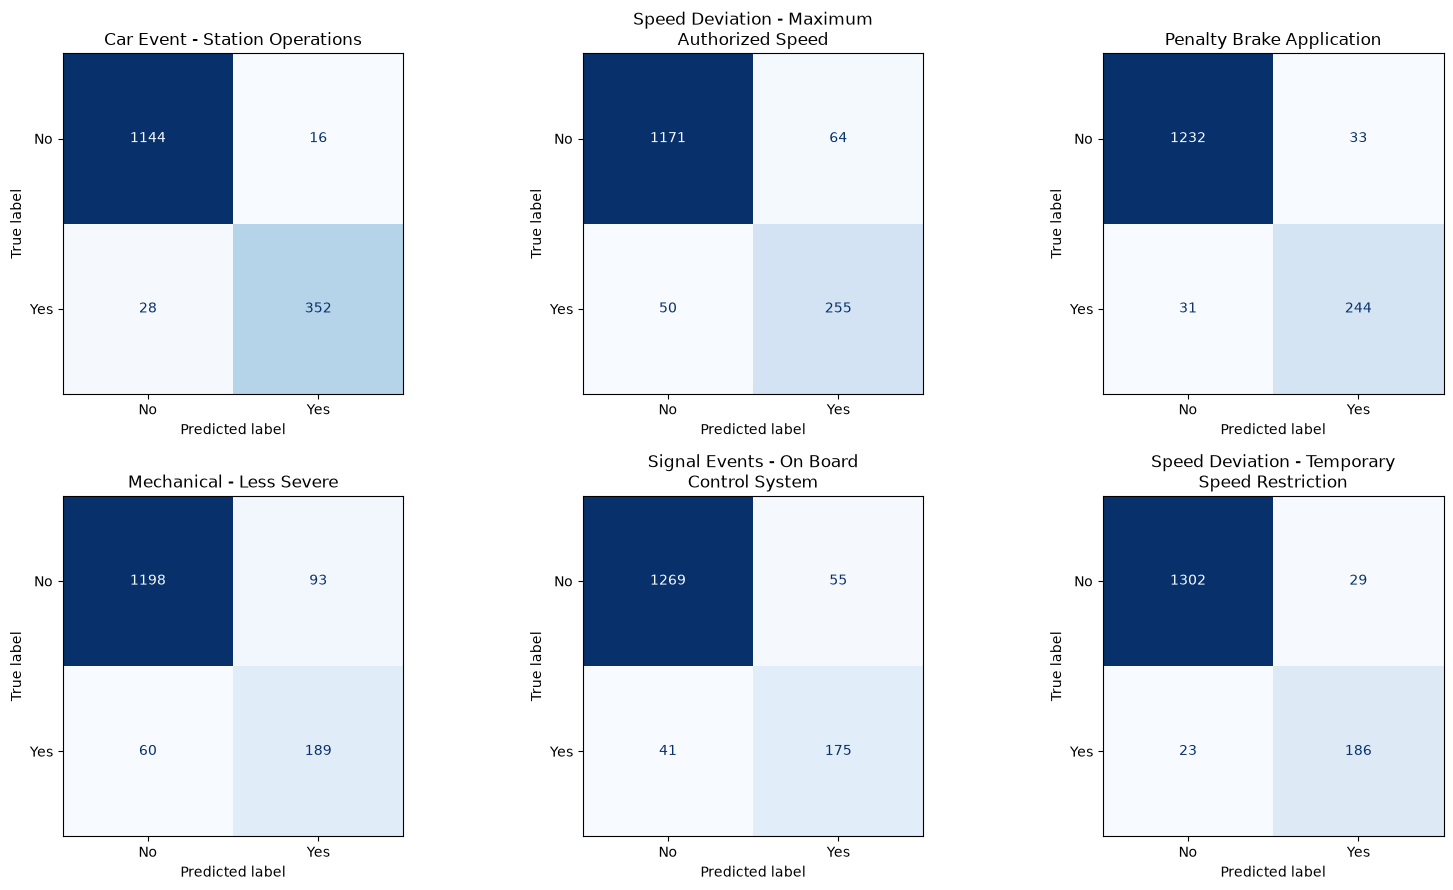

In [16]:
import matplotlib.pyplot as plt
from sklearn.metrics import multilabel_confusion_matrix, ConfusionMatrixDisplay
from textwrap import fill

cm = multilabel_confusion_matrix(y_true, y_pred)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for i, ax in enumerate(axes.flat):
    ConfusionMatrixDisplay(
        confusion_matrix=cm[i],
        display_labels=["No", "Yes"]
    ).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")

    ax.set_title(fill(TARGETS[target_names[i]].split(" / ")[-1], 30))

plt.tight_layout()
plt.show()

In [17]:
results.to_csv(results_dir / f"seed_{SEED}.csv", index=False)

summary = summary_markdown(
    f"{results_dir.name}: BERT on the reporter narratives",
    [
        f"{MODEL_NAME}, CLS vector, dropout, one linear layer with six outputs.",
        f"Reporter narratives only, cut to {MAX_LENGTH} tokens.",
        f"Seed {SEED}, batch {BATCH_SIZE} x {ACCUMULATE} accumulation, best epoch {best_epoch} "
        f"(validation mean AP {best_ap:.3f}).",
        f"Micro F1 {micro_f1:.3f}, macro F1 {macro_f1:.3f}.",
    ],
    results
)

(results_dir / "summary.md").write_text(summary, encoding="utf-8")

print(summary)
print("Summary to share:", results_dir / "summary.md")

# text_only: BERT on the reporter narratives

- bert-base-uncased, CLS vector, dropout, one linear layer with six outputs.
- Reporter narratives only, cut to 512 tokens.
- Seed 42, batch 16 x 1 accumulation, best epoch 5 (validation mean AP 0.868).
- Micro F1 0.843, macro F1 0.836.
- All numbers are test scores. Each event's yes/no cutoff was picked on validation.

## Average over the events

| Model | Average F1 | Mean AP |
|---|---|---|
| BERT | 0.836 | 0.892 |

## F1 per event

| Event | BERT |
|---|---|
| Station Ops | 0.941 |
| Speed - MAS | 0.817 |
| Emerg/Penalty Brake | 0.884 |
| Mechanical (less) | 0.712 |
| Signal - OBCS | 0.785 |
| Speed - TSR | 0.877 |
| Average | 0.836 |

## AP per event

| Event | BERT |
|---|---|
| Station Ops | 0.982 |
| Speed - MAS | 0.872 |
| Emerg/Penalty Brake | 0.934 |
| Mechanical (less) | 0.782 |
| Signal - OBCS | 0.851 |
| Speed - TSR | 0.930 |
| Average | 0.892 |

## Precision per event

| Event | BERT |
|---|---|
| Station Ops | 0.957 |
| Spee